In [12]:
from pathlib import Path
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
file_path = Path("../data/h_m51_v_s20_drz_sci.fits")

print("File found:", file_path.exists())

with fits.open(file_path) as hdul:
    hdul.info()

File found: True
Filename: ../data/h_m51_v_s20_drz_sci.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1763   (2150, 3050)   float32   


In [14]:
with fits.open(file_path) as hdul:
    image = np.array(hdul[0].data, dtype=float)

print("Array shape:", image.shape)
print("Minimum pixel value:", np.nanmin(image))
print("Maximum pixel value:", np.nanmax(image))

Array shape: (3050, 2150)
Minimum pixel value: -0.0563092902302742
Maximum pixel value: 228.00318908691406


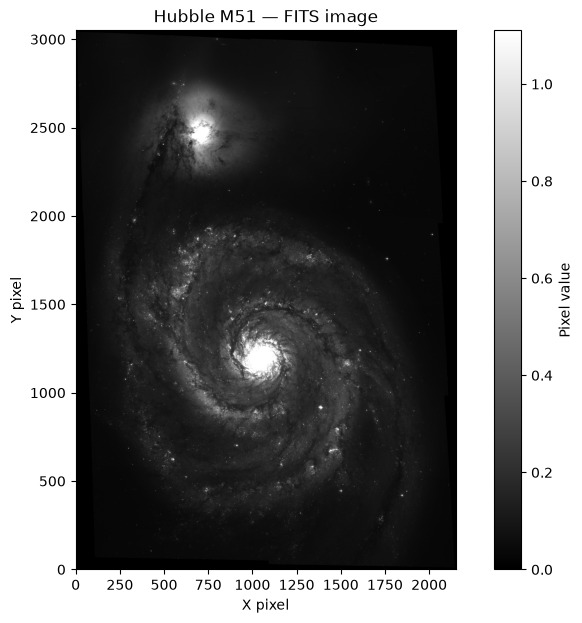

In [15]:
low, high = np.nanpercentile(image, [1, 99.5])

plt.figure(figsize=(10, 7))
plt.imshow(
    image,
    origin="lower",
    cmap="gray",
    vmin=low,
    vmax=high
)
plt.colorbar(label="Pixel value")
plt.title("Hubble M51 — FITS image")
plt.xlabel("X pixel")
plt.ylabel("Y pixel")
plt.show()